In [2]:
import numpy as np 
import math
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import odeint
from scipy.integrate import solve_ivp
#%matplotlib notebook
plt.rcParams["figure.figsize"] = (7,4)

Simulation de systèmes dynamiques non lisses
==============================


Le cours se focalise sur l'étude de systèmes dynamiques réguliers, c'est-à-dire $\dot{x}=f(x)$ avec $f$ au moins continue, et le plus souvent continûment différentiable. Le but de ce projet est de découvrir des systèmes moins réguliers, dits *non-lisses*. Il existe une myriade de modélisations de ces systèmes mais on peut distinguer différents *niveaux* d'irrégularité:

 - $f$ est continue mais non différentiable en certains points (on parle de *nonsmooth dynamics of type 1*, i.e., *NSD1*) : cela peut arriver dans la modélisation d'écoulements par exemple. Dans ce cas, les solutions $t\mapsto x(t)$ restent $C^1$ mais leur simulation peut déjà se compliquer.

 - $f$ est discontinue en certains points, ou le long de certaines surfaces (on parle de *NSD2*) : ceci apparaît typiquement en mécanique lors de la modélisation de contacts et friction entre solides, ou dans la modélisation de circuits électriques contenant des diodes par exemple. Dans ce cas, les solutions $t\mapsto x(t)$ sont toujours (absolument) continues mais non différentiables, le schéma numérique doit détecter des changements de *mode*.

 - les solutions $t\mapsto x(t)$ sont elles-mêmes discontinues, présentant des *sauts*  à certains instants ou lorsqu'elles rencontrent certaines surfaces, et il faut ajouter à $f$ un modèle de ces sauts (on parle de *NSD3*) : ceci apparaît typiquement avec les systèmes mécaniques à impact.

L'étude mathématique de ces sytèmes est très complexe, faisant appel à des outils qui nous mèneraient trop loin de ce cours (inclusions différentielles, complémentarité, analyse convexe, *measure differential inclusions*, etc), notre but est seulement d'en découvrir certains aspects à travers des exemples iconiques. Les curieux peuvent se référer à la documentation fournie par 

https://www.inria.fr/en/modelling-mechanics-simulation-fibres

https://www.inria.fr/en/tripop

ou aux ouvrages de références tels que

https://link.springer.com/book/10.1007/978-94-015-7793-9

https://link.springer.com/book/10.1007/978-3-540-44398-8 




## Dynamique non différentiable (NSD1)

Reprenons la loi de Toriccelli étudiée en TD et modélisant (modulo reparamétrisation) l'écoulement d'un fluide dans un réservoir
$$
\dot{x} = - \sqrt{|x|} \tag{1}
$$

**Question 1** Coder un schéma Euler explicite permettant de simuler une équation différentielle $\dot{x}=f(x,t)$ à partir d'une condition initiale $x_0$ au temps $t_0$ jusqu'au temps $t_f$ avec un pas de temps $dt$. 

In [3]:
def euler_explicit(f,x0,t0,tf,dt):
    time = np.arange(t0, tf, dt)
    sol = np.zeros(len(time))
    sol[0] = x0
    for i in range(1, len(time)) :
        sol[i] = sol[i-1] + dt * f(sol[i-1], time[i-1])
    return time, sol

**Question 2** L'utiliser pour simuler un écoulement d'une hauteur initiale $x_0=10$ pendant 10 unités de temps. Tracer la solution obtenue. Est-elle celle que l'on attend ? Les solver ''odeint'' ou ''solve_ivp" de scipy fait-il mieux ? Expliquer pourquoi. Proposer une façon de simuler *la* solution *physique*.



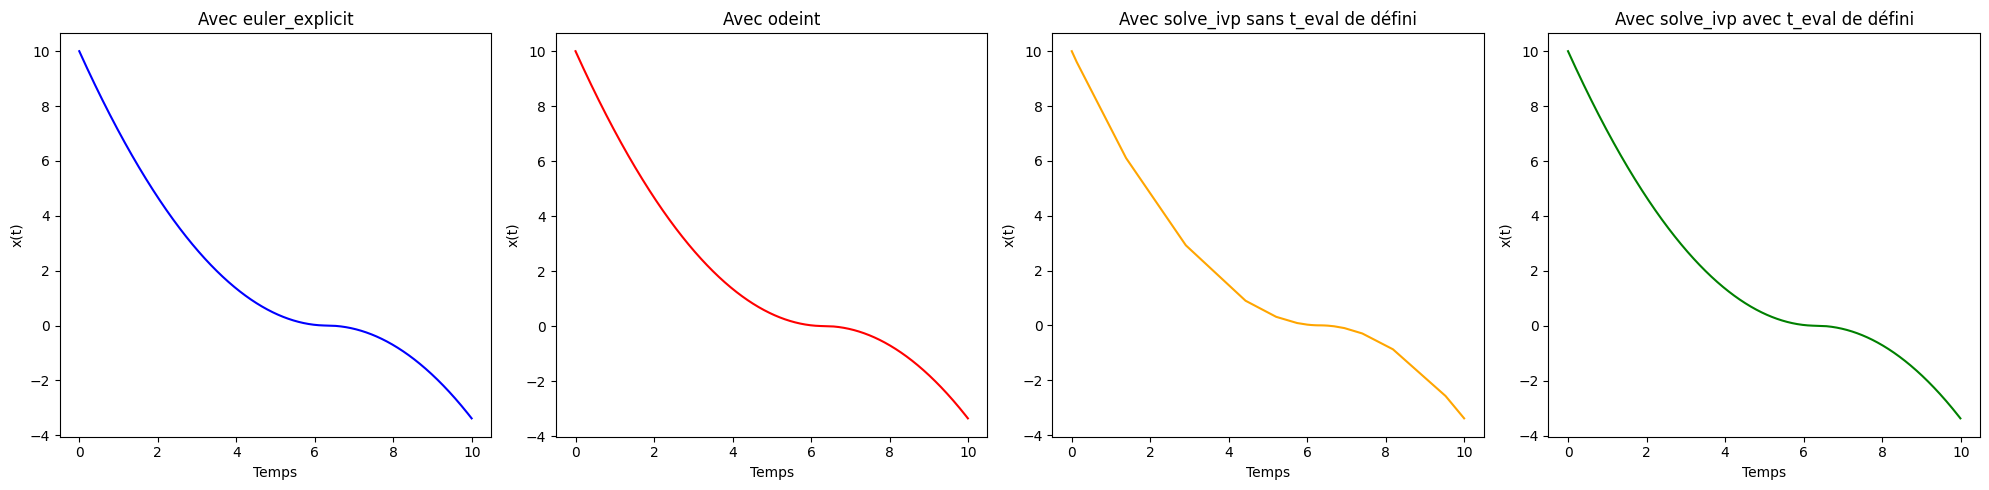

In [4]:
def f_toriccelli(x, t):
    return - np.sqrt(np.abs(x))

def f_toriccelli_solve_ivp(t, x):
    return f_toriccelli(x, t)

time, y_sol = euler_explicit(f_toriccelli, 10, 0, 10, 0.01)
y_sol_odeint = odeint(f_toriccelli, 10, time)
y_sol_solve_ivp_without_t_eval = solve_ivp(f_toriccelli_solve_ivp, (0., 10.), [10])
y_sol_solve_ivp_with_t_eval = solve_ivp(f_toriccelli_solve_ivp, (0., 10.),[10],  t_eval=time)

fig, axes = plt.subplots(nrows=1, ncols=4,figsize=(20, 5))
colors = ['blue', 'red', 'orange', 'green']
y_sol_tab = [y_sol, y_sol_odeint, y_sol_solve_ivp_without_t_eval.y[0,:], y_sol_solve_ivp_with_t_eval.y[0,:]]
times = [time, time, y_sol_solve_ivp_without_t_eval.t, y_sol_solve_ivp_with_t_eval.t]
for i in range(4):
    axes[i].plot(times[i], y_sol_tab[i], color=colors[i])
    axes[i].set_xlabel("Temps")
    axes[i].set_ylabel("x(t)")

axes[0].set_title("Avec euler_explicit")
axes[1].set_title("Avec odeint")
axes[2].set_title("Avec solve_ivp sans t_eval de défini")
axes[3].set_title("Avec solve_ivp avec t_eval de défini")

plt.tight_layout()

plt.show()

Le résultat n'est pas exactement ce à quoi l'on s'attend concernant l'écoulement d'un fluide. En effet, la fonction solution $x$ prend **des valeurs negatives** ce qui est incohérent physiquement, car x correspond à la hauteur du fluide.

On observe par ailleurs que les solvers `odeint` et `solve_ivp` ne fournissent pas de solution plus satisfaisante que `euler_explicit` : les courbes obtenues sont similaires, et x prend aussi des valeurs négatives.

L'explication réside dans deux points clefs :
- La fonction racine carrée n'est pas $C^1$ au voisinage de 0 (ni lipschitzienne). On ne peut pas appliquer le théorème de Cauchy-Lipschitz avec $x_0 = 0$ pour condition initiale. Dans les faits, il n'y a pas unicité de la solution. En effet, les deux fonctions $x_1$ et $x_0$ définies sur $\mathbb{R}$ par :
  $$\forall t \in \mathbb{R}, x_0(t) = 0$$
  $$\forall t \in \mathbb{R}, x_1(t) = \begin{cases} 0 & \text{si } t < 0 \\ -\left(\frac{t}{2}\right)^2 & \text{si } t \geq 0 \end{cases}$$
  sont deux solutions différentes de l'équation différentielle ayant pour condition initiale $x_0 = 0$. Cette équation étant autonome, ces possibilités illustrent les alternatives au moment où $x(t) = 0$.
- La méthode `euler_explicit` comme les deux solvers `odeint` et `solve_ivp` ont recours à une discretisation. Au voisinage de 0, un pas traversant cette valeur peut entrainer une valeur négative. Une fonction solution étant décroissante ($\dot{x}$ négative), on aboutit dès lors à des situations telles que celle représentée sur le graphe ci-dessus par exécution de notre code. Ce risque d'erreur lié à la discrétisation est par ailleurs d'autant plus grand que la dérivée de la fonction racinée carrée tend vers l'infini en 0 (pente 'infinie'!)

Il s'agit maintenant de proposer une façon de modéliser la solution physique.
On peut penser à deux méthodes :
- $\text{(a)}$ Utiliser les paramètres `events` et `terminal` de la fonction solve_ivp.
- $\text{(b)}$ Modifier la fonction `f_torricceli`. On peut de résoudre à la place de l'équation différentielle initiale l'équation différentielle suivante : $$\dot{x} = \begin{cases} -\sqrt{x} & \text{si } x > 0 \\ 0 & \text{si } x \leq 0 \end{cases}$$

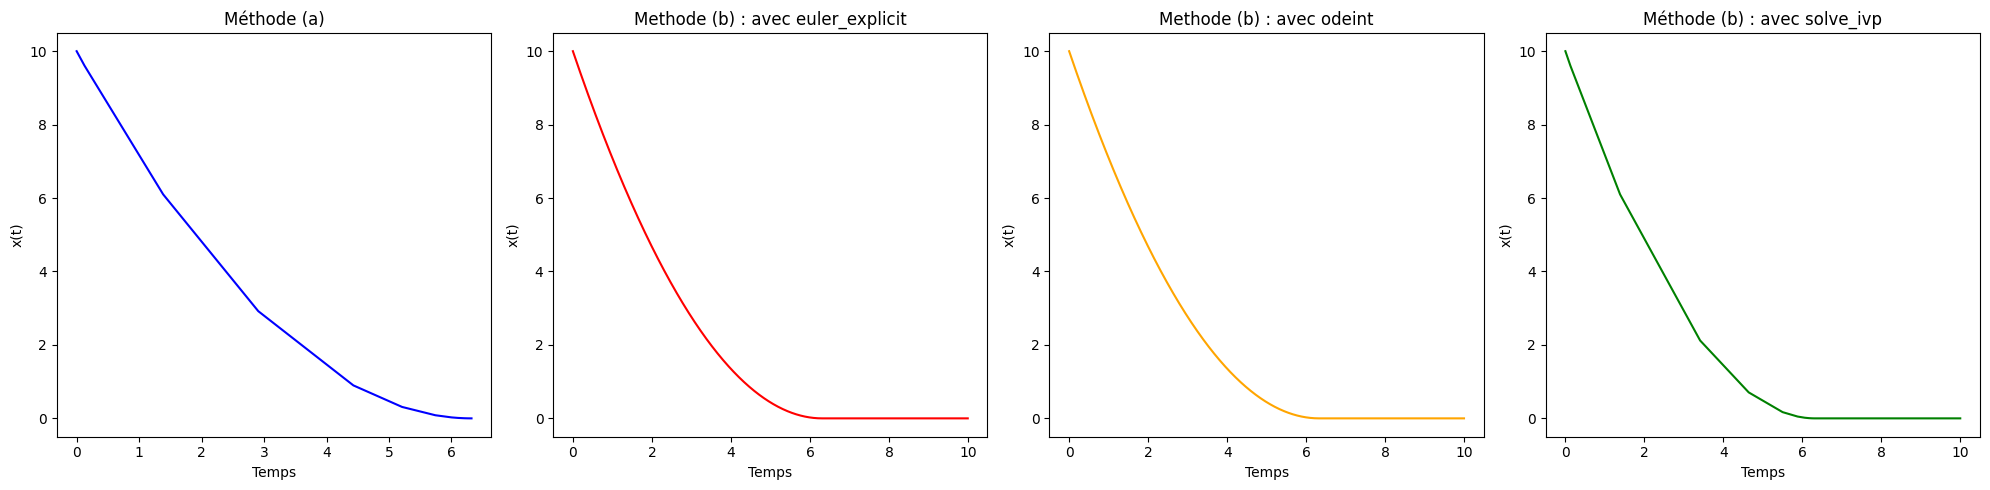

In [5]:
#Methode (a)
def event_fct(t, x):
    return x

event_fct.terminal = True

sol_a=solve_ivp(f_toriccelli_solve_ivp, (0., 10.), [10.], events=event_fct)

time_a, y_sol_a = sol_a.t, sol_a.y

#Methode (b)
def f_toriccelli_modified(x, t):
    if x<=0:
        return 0.
    else:
        return - np.sqrt(x)
    
def f_toriccelli_modified_solve_ivp(t, x):
    return f_toriccelli_modified(x, t)

time_modified, y_sol_modified = euler_explicit(f_toriccelli_modified, 10, 0, 10, 0.01)
y_sol_odeint_modified = odeint(f_toriccelli_modified, 10, time_modified)
y_sol_solve_ivp_modified = solve_ivp(f_toriccelli_modified_solve_ivp, (0., 10.), [10])

fig, axes = plt.subplots(nrows=1, ncols=4,figsize=(20, 5))
y_sol_tab_2 = [y_sol_a[0, :], y_sol_modified, y_sol_odeint_modified, y_sol_solve_ivp_modified.y[0, :]]
times_2 = [time_a, time_modified, time_modified,y_sol_solve_ivp_modified.t]

for i in range(4):
    axes[i].plot(times_2[i], y_sol_tab_2[i], color=colors[i])
    axes[i].set_xlabel("Temps")
    axes[i].set_ylabel("x(t)")

axes[0].set_title("Méthode (a)")
axes[1].set_title("Methode (b) : avec euler_explicit")
axes[2].set_title("Methode (b) : avec odeint")
axes[3].set_title("Méthode (b) : avec solve_ivp")

plt.tight_layout()

plt.show()

On peut maintenant tracer toutes ces courbes sur un même graphe

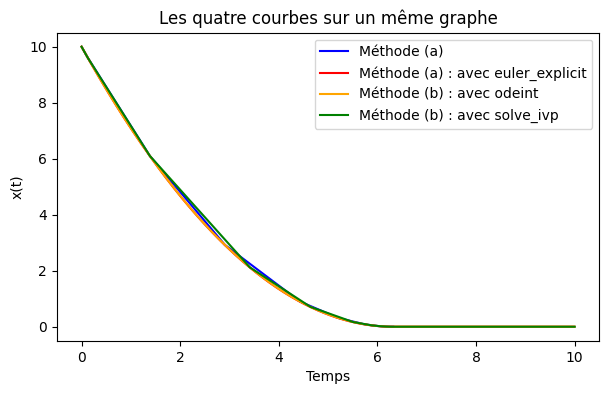

In [6]:
fig, axe = plt.subplots()
labels = ["Méthode (a)", "Méthode (a) : avec euler_explicit", "Méthode (b) : avec odeint", "Méthode (b) : avec solve_ivp"]
for i in range(4):
    axe.plot(times_2[i], y_sol_tab_2[i],label=labels[i],color=colors[i])
axe.set_xlabel("Temps")
axe.set_ylabel("x(t)")
axe.set_title("Les quatre courbes sur un même graphe")
axe.legend()
plt.show()

On remarque que les quatres courbes sont bien superposées, et prennent des valeurs positifs. Cela est cohérent. Le seul défaut de la méthode (a) est que la fonction s'arrête dès que $x(t) = 0$ tandis que les trois autres courbes continuent en restant constantes égales à 0 dès que $x(t) = 0$.
Le fait que la méthode (a) se superpose avec la méthode (b) nous conforte dans le choix de la nouvelle équation différentielle de la méthode (b).

En pratique, on essaye toujours de se ramener à une modélisation *bien posée* dont les solutions existent et sont uniques (ajout de contraintes ou régularisation, par exemple). Ici, on pourrait par exemple considérer plutôt
$$
\dot{x} = - {\rm sign}(x) \sqrt{|x|} \tag{2}
$$
avec ${\rm sign}(0)$ arbitraire. 

**Question 3** Montrer que pour toute condition initiale dans $\mathbb{R}$, (2) admet une unique solution maximale en temps positif définie sur $\mathbb{R}_{\geq 0}$, et qu'elle correspond à la solution ``physique'' attendue précédemment pour des conditions initiales positives. Justifier que l'on parle de "convergence globale vers 0 en temps fini". Illustrer ce phénomène en simulation. Ce comportement serait-il possible pour $\dot{x}=f(x)$ avec $f$ continûment différentiable ?


On définit :
$$\begin{equation*}
    f : \begin{array}{ccl}
        (J = \mathbb{R}) \times \mathbb{R} & \longrightarrow & \mathbb{R} \\
        (t, x) & \longmapsto & -\text{sign}(x) \sqrt{|x|}
    \end{array}
\end{equation*}$$
La fonction $f$ est continue.
Résoudre $\text{(2)}$ sur $\mathbb{R}_{\geq 0}$ revient à résoudre l'équation différentielle suivante sur $\mathbb{R}_{\geq 0}$ :
$$
\dot{x} = f(t, x)
$$

Soit $x_0 \in \mathbb{R}$. Montrons que $\text{(2)}$ admet une unique solution maximale en temps positif définie sur $\mathbb{R}_{\geq 0}$ pour la condition initiale $x_0$ à $t_0=0$.

<u>Existence :</u> D'après le théorème de Peano-Arzelà, puisque f est continue, il existe une solution au problème de Cauchy défini par $f$ et $(t_0,x_0)$. D'après le théorème sur le domaine maximal d'existence, il existe $x_m$ une solution maximale définie sur $\left] \tau_m^-, \tau_m^+ \right[$ où $\tau_m^-,\tau_m^+\in \mathbb{R} \cup \{ -\infty, +\infty \}$. Montrons que  $\left] \tau_m^-, \tau_m^+ \right[ = J$. Il suffit de montrer que $f$ a une croissance au plus affine. Montrons que :
$$\forall\, t \in \mathbb{R},\ \forall\, x \in \mathbb{R},\ |f(t,x)| < |x| + 1.$$
Soit $t, x \in \mathbb{R}$.
- Si $|x| \leq 1$ : Alors $\sqrt{|x|} \leq 1$ donc $|f(t,x)| = \sqrt{|x|} \leq |x| + 1$ car $|x| \geq 0$. 
- Sinon, $|x| > 1$ : Alors $\sqrt{|x|} \leq |x|$ donc $|f(t,x)| = \sqrt{|x|} \leq |x| + 1$ car $1 \geq 0$.

Ainsi, $f$ est continue et a une croissance au plus affine donc $\left] \tau_m^-, \tau_m^+ \right[ = J$.  
Par restriction de $x_m$, une solution maximale de $\text{(2)}$ sur $\mathbb{R}_{\geq 0}$ est définie sur $\mathbb{R}_{\geq 0}$. 

Avant de prouver l'unicité de la solution maximale, prouvons le résultat suivant, que l'on notera $(P)$ : Soit $x : \mathbb{R}_{\geq 0} \to \mathbb{R}$ une solution maximale de $\text{(2)}$ sur $\mathbb{R}_{\geq 0}$ pour la conditions initiale $(0, x_0)$. Alors:
$$\forall\, t_{0} \in \mathbb{R}_{\geq 0},\ 
\bigl(x(t_{0}) = 0\bigr) \;\Rightarrow\; 
\bigl(\forall\, t \ge t_{0},\ x(t) = 0\bigr).
$$
  <u>Preuve de $(P)$ :</u> Soit $x : \mathbb{R}_{\geq 0} \to \mathbb{R}$ une solution maximale de $\text{(2)}$ sur  $\mathbb{R}_{\geq 0}$ pour la conditions initiale $(0, x_0)$. Soit $t_0 \in \mathbb{R}_{\geq 0}$. On suppose que $x(t_0) = 0$.Montrons que $\forall\, t \ge t_{0},\ x(t) = 0$. Par l'absurde, supposons qu'il existe $t_1 \geq t_0$ tel que $x(t_1) \neq 0$. On pose $X =\left(x_{\mid [0,\,t_{1}]}\right)^{-1}\!\bigl(\{0\}\bigr)$. Alors $X$ est naturellement borné, et fermé car $x$ est continue. On peut donc définir $t_2 = max(X)$.
  - Si $x(t_1) > 0$ : Alors $\forall\, t \in \bigl[t_2,\,t_{1}\bigr],\ x(t) \geq 0$. En effet, par l'absurde, supposons qu'il existe $t_3 \in \bigl[t_2,\,t_{1}\bigr]$ tel que $x(t_3) < 0$. Par théorème des valeurs intermédiaire, il existe $t_4 \in \bigl[t_3,\,t_{1}\bigr]$ tel que $x(t_4) = 0$. C'est absurde par maximalité de $t_2$. Donc $\forall\, t \in \bigl(t_2,\,t_{1}\bigr),\ x(t) \geq 0$. Donc d'après $\text{(2)}$, $\forall\, t \in \bigl[t_2,\,t_{1}\bigr],\ \dot{x}(t) \leq 0$. Donc $x$ est décroissante sur $\bigl[t_2,\,t_{1}\bigr]$. Donc $x(t_1) \leq x(t_2) = 0$. C'est absurde.
  - Sinon, $x(t_1) < 0$. Par échange de $x$ en $-x$ qui est aussi solution de $\text{(2)}$, on se ramène au cas précédent et on aboutit à une absurdité.   

Donc $\forall\, t \ge t_{0},\ x(t) = 0$.

Passons maintenant à la preuve de l'unicité.

<u>Unicité :</u> Soit $x_1, x_2 : \mathbb{R}_{\geq 0} \to \mathbb{R}$ deux solutions maximales de $\text{(2)}$ sur $\mathbb{R}_{\geq 0}$ pour la conditions initiale $(0, x_0)$. Montrons que $x_1 = x_2$.  
- <u>Si $x_0 \neq 0$</u> Par l'absurde, supposons que $x_1 \neq x_2$. On pose $X = \{\, t \in \mathbb{R}_{\geq 0} \mid x_{1}(t) = 0 \text{ ou } x_{2}(t) = 0 \,\}$ et $Y = \{\, t \in \mathbb{R}_{\geq 0} \mid x_{1}(t) \neq x_{2}(t) \,\}$. Alors $Y \neq \varnothing$.
  - <u>Si $X = \varnothing$ :</u> Alors $x_1, x_2 : \mathbb{R}_{\geq 0} \to \mathbb{R}^{*}$. Donc si $g = f_{\mid \mathbb{R}\times \mathbb{R}^{*}}$, alors  $x_1$ et $x_2$ sont deux solutions du problème de Cauchy défini par g et $(0, x_0)$. Or g est continuement différentiable (car $0 \notin \mathbb{R}^{*}$), donc d'après le théorème de Cauchy-Lipschitz, $x_1 = x_2$. C'est absurde car $x_1 \neq x_2$
  - <u>Sinon,  $X \neq \varnothing$ :</u> Alors $X$ et $Y$ sont tous les deux minorés et non vides. On note $min_x$ et $min_y$ leurs bornes inférieures respectives. $X$ est fermé (car $X = \bigl(|x_1|\,|x_2|\bigr)^{-1}\!\bigl(\{0\}\bigr)$ et $\bigl(|x_1|\,|x_2|\bigr)$ est continue) donc $min_x \in X$. Donc $x_{1}(min_x) = 0 \text{ ou } x_{2}(min_x) = 0$.
    - <u>Montrons que $min_x \leq min_y$.</u> Par l'absurde, supposons que $min_x > min_y$. Il existe donc $t_{diff} \in Y$ tel que $t_{diff} \leq \tfrac{min_y + min_x}{2} < min_x$ tel que  $x_{1}(t_{diff}) \neq x_{2}(t_{diff})$. On pose $I = \bigl[\,0,\, \tfrac{t_{\mathrm{diff}} + \min_{x}}{2}\,\bigr[$. Alors, si $g = f_{I\times \mathbb{R}^{*}}$ les restrictions de $x_1$ et $x_2$ à $I$ sont solution du problème de Cauchy défini par $g$ et $(0, x_0)$ car $x_1$ et $x_2$ sont non nulle sur $I$ puisque $\tfrac{t_{\mathrm{diff}} + \min_{x}}{2} < min_x$. Comme $g$ est continuement différentiable et d'après le théorème de Cauchy-Lipschitz, ces deux applications sont égales. En particulier $x_{1}(t_{diff}) = x_{2}(t_{diff})$. C'est absurde car $x_{1}(t_{diff}) \neq x_{2}(t_{diff})$. Donc $min_x \leq min_y$.  
    - <u>Montrons que $min_x > min_y$.</u> Par l'absurde, supposons que $min_x \leq min_y$. On a $x_{1}(min_x) = 0 \text{ ou } x_{2}(min_x) = 0$. Or $min_x \leq min_y$ donc $x_{1}(min_x) = x_{2}(min_x)$. En effet, si tel n'était pas le cas, vu que $Y$ est un ouvert ($Y = \bigl(|x_{1}-x_{2}|\bigr)^{-1}\!\bigl(\mathbb{R}^{*}\bigr)$ et $|x_{1}-x_{2}|$ est continue), on aurait $min_x > min_y$.  
      Or $x_{1}(min_x) = 0 \text{ ou } x_{2}(min_x) = 0$ donc $x_{1}(min_x) = x_{2}(min_x)=0$. Alors, d'après $(P)$, $\forall\, t \ge min_x,\ x_1(t) = x_2(t) = 0$. Or $\forall\, t < min_x,\ x_1(t) = x_2(t)$ car $min_x \leq min_y$. Donc $x_1 = x_2$. C'est absurde car $x_1 \neq x_2$. Donc $min_x > min_y$.   

    Donc $min_x \leq min_y$ et $min_x > min_y$. C'est absurde.
  
  Donc $x_1 = x_2$. 

- <u>Sinon, $x_0 = 0$:</u> Alors, $x_1(0) = x_2(0) = 0$ donc d'après $(P)$, $\forall t \geq 0, x_1(t) = x_2(t) = 0$ donc $x_1 = x_2$


Ainsi, nous venons de prouver que $\text{(2)}$ admet une unique solution maximale en temps positif définie sur $\mathbb{R}_{\geq 0}$ pour la condition initiale $x_0$ à $t_0=0$.

Pour une condition intiale positive, cette solution correspond bien à la solution physique car d'après la propriété $(P)$, une fois que $0$ a été atteint, la fonction solution demeure constante égale à 0. Une fois que le réservoir est vide, il reste vide ! De plus, en conséquence, la fonctions solution est toujours décroissante avec une condition initiale positive. On ne fait que vider de l'eau !

Donnons une expression explicite de cette solution. Soit $x_0 \in \mathbb{R}$.On pose : 
$$\begin{aligned}
y_{x_0}:\ \mathbb{R}_+ &\to \mathbb{R}\\
t &\mapsto
\begin{cases}
\operatorname{sign}(x_0)\left(\sqrt{\lvert x_0\rvert}-\dfrac{t}{2}\right)^2, & 0\le t\le 2\sqrt{\lvert x_0\rvert},\\
0, & t>2\sqrt{\lvert x_0\rvert}.
\end{cases}
\end{aligned}
$$

Montrons que $y_{x_0}$ est l'unique solution de $\text{(2)}$ définie sur $\mathbb{R}_{\geq 0}$ pour la condition initiale $(0, x_0)$. Il suffit de montrer qu'elle est solution d'après ce que l'on vient de prouver.  D'une part, $y_{x_0}$ est naturellement continue sur $\mathbb{R}_{\geq 0}$

D'après les théorèmes usuels, $y_{x_0}$ est dériviable sur $\left[0,\; 2\sqrt{\lvert x_0\rvert}\right[$ et $\left]2\sqrt{\lvert x_0\rvert},\ +\infty\right[$ et
$$\forall t\in \left[0,\; 2\sqrt{\lvert x_0\rvert}\right[,\ y_{x_0}^{'}(t) = -\operatorname{sign}(x_0)\left(\sqrt{\lvert x_0\rvert}-\dfrac{t}{2}\right)$$
$$\forall t\in \left]2\sqrt{\lvert x_0\rvert},\ +\infty\right[,\ y_{x_0}^{'}(t) = 0$$

Donc $y_{x_0}$ est dérivable sur $\mathbb{R}_+ \setminus \left\{2\sqrt{\lvert x_0\rvert}\right\}$. De plus, naturellement, $y_{x_0}^{'}$ tend vers $0$ quand $t$ tend vers $2\sqrt{\lvert x_0\rvert}$. Enfin, $y_{x_0}$ est continue sur $\mathbb{R}_{\geq 0}$. Donc d'après le théorème de la limite de la dérivée, $y_{x_0}$ est dériviable en $2\sqrt{\lvert x_0\rvert}$ et sa dérivée en ce point vaut $0$. Ainsi : 

$$
\forall\, t\in \mathbb{R}_{\ge 0},\quad
y_{x_0}'(t)=
\begin{cases}
-\mathrm{sign}(x_0)\left(\sqrt{|x_0|}-\frac{t}{2}\right) & 0\le t\le 2\sqrt{|x_0|} \\
0 & t>2\sqrt{|x_0|}
\end{cases}
$$


Dès lors, on remarque naturellement que $y_{x_0}$ est solution de $\text{(2)}$. On peut donc parler de "convergence globale vers 0 en tend fini" car cette unique solution tend vers $0$ en $+\infty$ et la valeur $0$ est atteinte en temps fini $2\sqrt{\lvert x_0\rvert}$ et ne quitte plus cette valeur ensuite.

Illustrons maintenant cela grâce à une simulation. 

/var/folders/0t/f6l753z163n4mby3fhmm1r3m0000gn/T/ipykernel_63823/2489242688.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return - (1 if x >= 0 else - 1) * math.sqrt(abs(x))


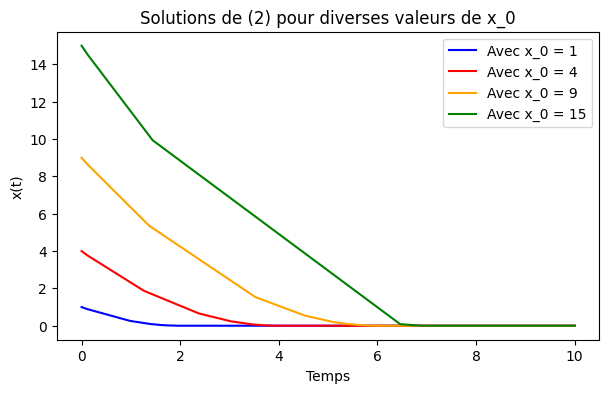

In [7]:
def f_q3(t,x):
    return - (1 if x >= 0 else - 1) * math.sqrt(abs(x))

fig, axe = plt.subplots()

times = []
y_sols = []

x_0s = [1, 4, 9, 15]
colors = ['blue', 'red', 'orange', 'green']

for (x_0, i) in zip(x_0s, list(range(len(x_0s)))):
    label_x_0 = "Avec x_0 = %d" % x_0
    y_sol = solve_ivp(f_q3, (0., 10.), [x_0] )
    plt.plot(y_sol.t, y_sol.y[0, :], label=label_x_0, color=colors[i])

axe.set_xlabel("Temps")
axe.set_ylabel("x(t)")
axe.set_title("Solutions de (2) pour diverses valeurs de x_0")
axe.legend()
plt.show()

On observe bien que $0$ est à chaque fois atteint en temps fini, et que la propriété $\text{(P)}$ est bien vérifiée !

Cette convergence globale vers $0$ en temps fini serait-elle possible pour $\dot{x}=f(x)$ avec $f$ continûment différentiable ?

Soit $f : \mathbb{R} \times \mathbb{R} \to \mathbb{R}$ continuement différentiable, et $x$ une solution de l'équation différentielle $\text{(ED)}$ $\dot{x} = f(t, x)$. Prouvons la proriété $\text{(Q)}$ :
$$\bigl(x\text{ converge globalement vers 0 en temps fini}\bigr) \Rightarrow\ x = \tilde{0} \tag{Q}$$

où $\tilde{0}$ désigne la fonction constante égale à 0.

<u>Preuve :</u> On suppose que $x$ converge globalement vers $0$ en temps fini. Il existe donc $t_0$ tel que :
$$\forall\, t \ge t_{0},\ x(t) = 0
$$

Donc on a d'après les théorèmes usuels
$$\forall\, t \ge t_{0},\ \dot{x}(t) = 0
$$. 

De plus, d'après $\text{(ED)}$ :
$$\forall t \in \mathbb{R}, \dot{x}(t) = f(x(t)) \tag{α}$$
En appliquant cette dernière relation en  $t_0$, on obtient $f(0) = 0$. Par conséquent, $\tilde{0}$ est naturellement solution de $\text{(ED)}$. Plus particulièrement,  $\tilde{0}$ est solution du problème de Cauchy défini par $f$ est $(t_0, 0)$. Or, $x$ en est aussi une. Puisque $f$ est continument différentiable, le théorème de Cauchy Lipschitz nous assure que $x = \tilde{0}$.  

Donc $\text{(Q)}$ est vraie. 

On en déduit la réponse à la question initiale, résultat que l'on note $\text{(R)}$ : $\text{(ED)}$ admet une solution convergent globalement vers 0 en temps fini si et seulement si $f(0) = 0$, et si tel est le cas, celle-ci est unique et égale à $x = \tilde{0}$

<u>Preuve :</u>

- $\Rightarrow$: On suppose que $\text{(ED)}$ admet une solution $x$ convergent globalement vers $0$ en temps fini. D'après $\text{(Q)}$, $x = \tilde{0}$. D'après $\text{(ED)}$, la relation $\text{(α)}$ est vrai. En l'appliquant en $t = 0$, on obtient $f(0) = 0$


- $\Leftarrow$: On suppose que $f(0) = 0$. Alors $\tilde{0}$ est naturellement solution de $\text{(ED)}$. 

Par conséquent, puisque dans notre cas physique, des conditions initiales intéressantes sont strictement positives, on ne pourrait pas avoir de converence globale vers 0 en temps fini pour nos solutions.

Pour assurer la cohérence physique de nos solutions, il est donc important dans notre cas que $ff ne soit pas continuement différentiable.

## Dynamique discontinue (NSD2)



Passons maintenant à une irrégularité plus forte, lorsque la fonction $f$ décrivant l'équation différentielle $\dot{x}=f(x)$ est discontinue, c'est-à-dire lorsque la solution $x$ suit des dynamiques différentes selon les régions de l'espace (par exemple selon le sens du courant pour des diodes, selon le sens de la vitesse pour des frottements secs etc.). Un exemple emblématique de ce cas de figure est 
$$
\dot{x} = - k {\rm sign}(x) \tag{3}
$$
pour $k>0$ et la valeur de ${\rm sign}(0)$ à définir.

**Question 4** Démontrer que pour une valeur de ${\rm sign}(0)$ bien choisie, (3) admet, pour toute condition initiale $x_0\in \mathbb{R}$, une unique solution maximale $t\mapsto x(t)$ en temps positif définie sur $\mathbb{R}_{\geq 0}$ et convergeant en temps fini vers 0. L'expliciter.

On pose ${\rm sign}(0) = 0$.

Soit $x_0 \in \mathbb{R}$.
Soit $x$ une solution maximale de l'équation différentielle $\rm (3)$, de condition initiale $x(0) = x_0$. Notons $I \subset \mathbb{R}_{\geq 0}$ l'intervalle de définition de $x$.


**Cas 1 : $x_0 > 0$.**

Posons $t_0 = \left\{ {
    \begin{array}{cc}
    {\rm inf} \: \{t \in I | x(t) = 0\} & \text {si} \: \{t \in I | x(t) = 0\} \neq \emptyset \\
    {\rm sup} \: I & \text{sinon}
    \end{array}
} \right.$.

D'après $\rm (3)$, $\forall t \in [0, t_0[, \dot{x}(t) = - k$, i.e. $\forall t \in [0, t_0[, x(t) = - k t + x_0$. 

On en déduit que $t_0 = \frac{x_0}{k}$. On a bien $\frac{x_0}{k} \in I$ puisque $t \mapsto - k t + x_0$ est solution du problème sur $\left[0, \frac{x_0}{k}\right]$ et $I$ est maximal, donc $I \supset \left[0, \frac{x_0}{k}\right]$.

Supposons par l'absurde disposer de $t_2 > t_1 \geq t_0$ tels que $t_2 \in I$, $x(t_1) = 0$ et $\forall t \in ]t_1, t_2[, x(t) \neq 0$. Supposons par exemple que $\forall t \in ]t_1, t_2[, x(t) > 0$.

Alors $\forall t \in ]t_1, t_2[, \dot{x}(t) = - k$, d'où $\forall t \in ]t_1, t_2[, x(t) = - k (t - t_1) < 0$. C'est absurde, et on aboutit à une contradiction analogue en supposant que $x$ est strictement négatif sur $]t_1, t_2[$, donc $\forall t \in ]t_0, +\infty[ \cap I, x(t) = 0$.


**Cas 2 : $x_0 < 0$.**

Définissons $t_0$ comme précédemment.

D'après $\rm (3)$, $\forall t \in [0, t_0[, \dot{x}(t) = k$, i.e. $\forall t \in [0, t_0[, x(t) = k t + x_0$.

On en déduit que $t_0 = - \frac{x_0}{k}$, car par le même argument que précédemment, on a bien $- \frac{x_0}{k} \in I$.

On montre comme dans le cas 1 que $\forall t \in ]t_0, +\infty[ \cap I, x(t) = 0$.


**Cas 3 : $x_0 = 0$.**

On montre par l'absurde que $\forall t \in I, x(t) = 0$ en utilisant le même argument que précédemment.


**Conclusion**

Ainsi, dans tous les cas, $x = t \mapsto \left\{ {
    \begin{array}{cc}
    -{\rm sign}(x_0) k t + x_0 & \text {si} \: t < \frac{|x_0|}{k}\\
    0 & \text{sinon}
    \end{array}
} \right.$

On vérifie que cette expression est solution sur $\mathbb{R}_{\geq 0}$ entier, donc comme $I$ est maximal, on en déduit que $I = \mathbb{R}_{\geq 0}$. Cette solution maximale est unique d'après ce qui précède. Elle converge bien vers $0$ en temps fini puisque $x(t) = 0$ dès que $t \geq \frac{|x_0|}{k}$.

Considérons maintenant $\delta_m>0$ et l'équation différentielle perturbée
$$
\dot{x} = - k{\rm sign}(x) + \delta(t) \tag{4}
$$
pour $t\mapsto \delta(t)$ telle que $|\delta(t)|\leq \delta_m$ pour tout $t$.

**Question 5** Démontrer que si $k>\delta_m$, alors (4) admet toujours, pour toute condition initiale $x_0\in \mathbb{R}^*$ et quelle que soit la perturbation $\delta$ bornée par $\delta_m$, une unique solution maximale $t\mapsto x(t)$ en temps positif et convergeant en temps fini vers 0. Justifier que ces solutions pourraient être définie sur $\mathbb{R}_{\geq 0}$ si on acceptait que ${\rm sign}(0)$ puisse prendre n'importe quelle valeur entre -1 et 1.

Supposons $k > \delta_m$. Soient $x_0 \in \mathbb{R}^*$ et $\delta$ une perturbation bornée par $\delta_m$.
Soit $x$ une solution maximale de l'équation différentielle $\rm (4)$, de condition initiale $x(0) = x_0$. Notons $I \subset \mathbb{R}_{\geq 0}$ l'intervalle de définition de $x$.


**Cas 1 : $x_0 > 0$.**

Posons $t_0 = \left\{ {
    \begin{array}{cc}
    {\rm inf} \: \{t \in I | x(t) = 0\} & \text {si} \: \{t \in I | x(t) = 0\} \neq \emptyset \\
    {\rm sup} \: I & \text{sinon}
    \end{array}
} \right.$.

D'après $\rm (4)$, $\forall t \in [0, t_0[, \dot{x}(t) = - k + \delta(t)$. Ainsi, $\forall t \in [0, t_0[, \dot{x}(t) \leq - k + \delta_m$, d'où $\forall t \in [0, t_0[, x(t) \leq - (k - \delta_m) t + x_0$.

On en déduit que $t_0 \leq \frac{x_0}{k - \delta_m} < + \infty$ par continuité de $x$.

Suppposons par l'absurde disposer de $t_2 > t_1 \geq t_0$ tels que $t_2 \in I$, $x(t_1) = 0$ et $\forall t \in ]t_1, t_2[, x(t) \neq 0$. Supposons par exemple que $\forall t \in ]t_1, t_2[, x(t) > 0$.

Alors $\forall t \in ]t_1, t_2[, \dot{x}(t) = - k + \delta(t)$, d'où $\forall t \in ]t_1, t_2[, x(t) \leq - (k - \delta_m) (t - t_1) < 0$. C'est absurde, et on aboutit à une contradiction analogue en supposant que $x$ est strictement négatif sur $]t_1, t_2[$, donc $\forall t \in ]t_0, +\infty[ \cap I, x(t) = 0$. Ceci impose que $\forall t \in ]t_0, +\infty[ \cap I, \delta(t) = \dot{x}(t) = 0$.

Posons à présent $t_3 = \left\{ {
    \begin{array}{cc}
    {\rm inf} \: \{t \in I | t \geq t_0 \land \delta(t) \neq 0\} & \text {si} \: \{t \in I | t \geq t_0 \land \delta(t) \neq 0\} \neq \emptyset \\
    {\rm sup} \: I & \text{sinon}
    \end{array}
} \right.$. Dans la suite, pour alléger les notations, on considérera qu'un intervalle noté fermé en un point peut en fait être ouvert en ce point, en fonction de la situation particulière. D'après ce qui précède, on a donc $I \subset [0, t_3]$.

**Cas 2 : $x_0 < 0$.**

Définissons $t_0$ comme précédemment.

D'après $\rm (4)$, $\forall t \in [0, t_0[, \dot{x}(t) = k + \delta(t)$. Ainsi, $\forall t \in [0, t_0[, \dot{x}(t) \geq k - \delta_m$, d'où $\forall t \in [0, t_0[, x(t) \geq (k - \delta_m) t + x_0$.

On en déduit que $t_0 \leq \frac{x_0}{k - \delta_m} < + \infty$ par continuité de $x$.

On montre comme dans le cas 1 que $\forall t \in ]t_0, +\infty[ \cap I, x(t) = 0$.

Définissons $t_3$ comme précédemment. Par le même argument que ci-dessus, on a $I \subset [0, t_3]$.


**Conclusion**

Ainsi, $x$ est définie sur $[0, t_0]$, puis sur $]t_0, t_3] \cap I$ où elle est nulle. Or, on vérifie que la fonction coïncidant avec $x$ sur $I$ et nulle sur $]t_0, t_3]$ est solution du problème, donc comme $I$ est maximal, on en déduit que $I = [0, t_3]$.

Cette solution maximale est unique. En effet, si $y$ est une autre solution du problème sur $I$ intervalle maximal, alors $x - y$ est de dérivée nulle sur (presque tout) $\mathring I$, donc constante, or $x(0) = x_0 = y(0)$, donc la différence est nulle sur $I$ et $x = y$. La solution converge en temps fini vers $0$ car $\forall t \in [t_0, t_3], x(t) = 0$.

Acceptons de définir ${\rm sign}(0)$ comme une fonction de $\mathbb{R}_{\geq 0}$ à valeurs dans $]-1, 1[$ par ${\rm sign}(0) : t \mapsto \frac{\delta(t)}{k}$. Cette application est bien définie car $\forall t \in \mathbb{R}_{\geq 0}, |{\rm sign}(0)(t)| \le \frac{\delta_m}{k} < 1$. On a alors, en reprenant les notations précédentes, $\forall t \in ]t_0, +\infty[ \cap I, \dot{x}(t) = 0$, donc par maximalité de $I$, on aboutit à $I = \mathbb{R}_{\geq 0}$. Ainsi la solution pourrait être définie sur $\mathbb{R}_{\geq 0}$ si on acceptait que ${\rm sign}(0)$ puisse prendre n'importe quelle valeur entre $-1$ et $1$.

Ceci mène en fait à la notion d'*inclusion différentielle* $\dot{x}\in f(x)$, où la fonction signe serait ici une fonction *multivaluée*, c'est-à-dire à valeurs ensembliste (*set-valued map*), définie par
$$
{\rm Sign}(x) = \left\{
\begin{array}{ll}
{1} & \text{si x>0} \\
[-1,1] & \text{si x=0} \\
-1 & \text{si x<0}
\end{array}
\right.
$$
Ce genre de phénomène est utilisé en commande ou estimation par *mode-glissant* (*sliding mode*) pour stabiliser des systèmes dynamiques en temps fini et malgré la présence de perturbations inconnues ou d'incertitudes dans le modèle. Le prix à payer pour ce genre de système est une grande sensibilité au bruit et une difficulté accrue de les discrétiser et simuler.

*Pour la culture* : La théorie des inclusions différentielles a été développée par Filippov, voir https://link.springer.com/book/10.1007/978-3-319-28664-8. Elle a montré que le ``bon'' cadre pour qu'une inclusion différentielle ait de bonnes propriétés (notamment que des approximations de solutions convergent vers des solutions, c'est-à-dire la compacité séquentielle des solutions, permettant la discrétisation et simulation de ces systèmes) est lorsque $f$ est semi-continue supérieure, localement bornée et à valeurs convexes et fermées. D'où l'intervalle $[-1,1]$ pour ${\rm sign}(0)$ qui est le plus petit convexe fermé assurant la semi-continuité supérieure de ${\rm sign}$. 


**Question 6** Illustrer numériquement la convergence en temps finie globale et la robustesse aux perturbations de (4) à l'aide du schéma numérique de votre choix.

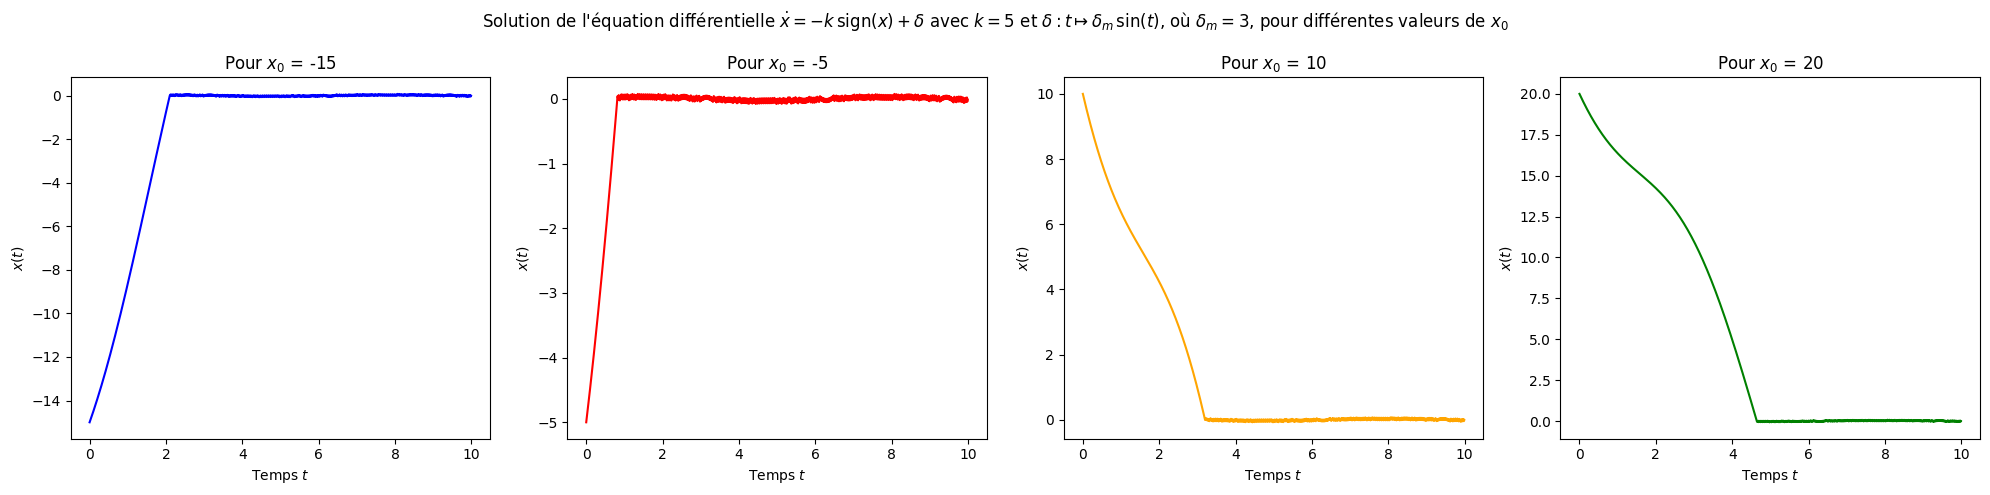

In [8]:
def f(x, t):
    k = 5
    delta_m = 3
    delta = delta_m * np.sin(t)
    return -k * np.sign(x) + delta
t0 = 0
tf = 10
dt = 0.01
x0 = [-15, -5, 10, 20]
fig, axes = plt.subplots(nrows=1, ncols=4,figsize=(20, 5))
colors = ['blue', 'red', 'orange', 'green']
for i in range(4) :
    t, x = euler_explicit(f, x0[i], t0, tf, dt)
    axes[i].plot(t, x, color=colors[i])
    axes[i].set_xlabel("Temps $t$")
    axes[i].set_ylabel("$x(t)$")
    axes[i].set_title(f"Pour $x_0$ = {x0[i]}")
fig.suptitle(r"Solution de l'équation différentielle $\dot{x} = - k \, {\rm sign}(x) + \delta$ avec $k = 5$ et $\delta : t \mapsto \delta_m \, {\rm sin}(t)$, où $\delta_m = 3$, pour différentes valeurs de $x_0$")
plt.tight_layout()
plt.show()

**Analyse**

***Convergence en temps fini globale :*** Quelle que soit la condition initiale $x_0$, on constate que la solution converge en temps fini vers $0$.

***Robustesse aux perturbations :*** La courbe n'est pas une ligne droite parfaite, ce qui illustre l'effet de la perturbation $\delta$. Cependant, la perturbation ne modifie pas la dynamique de convergence de la solution (on a $k > \delta_m$). On note par ailleurs des oscillations numériques de la solution autour de $x(t) = 0$, liées à la discrétisation et à l'imprécision du calcul numérique.

**Question 7** Illustrer et commenter le comportement du schéma d'Euler explicite autour de 0. On parle de phénomène de chattering. Que se passe-t-il si $k$ est grand ? Proposer un schema d'Euler implicite pour ce système et montrer qu'il permet d'éviter ce *chattering* et d'assurer une convergence numérique exacte vers 0.

Comme illustré à la question précédente, le schéma d'Euler explicite fournit des oscillations numériques autour de $0$ (en raison de la discrétisation et de l'imprécision du calcul numérique).

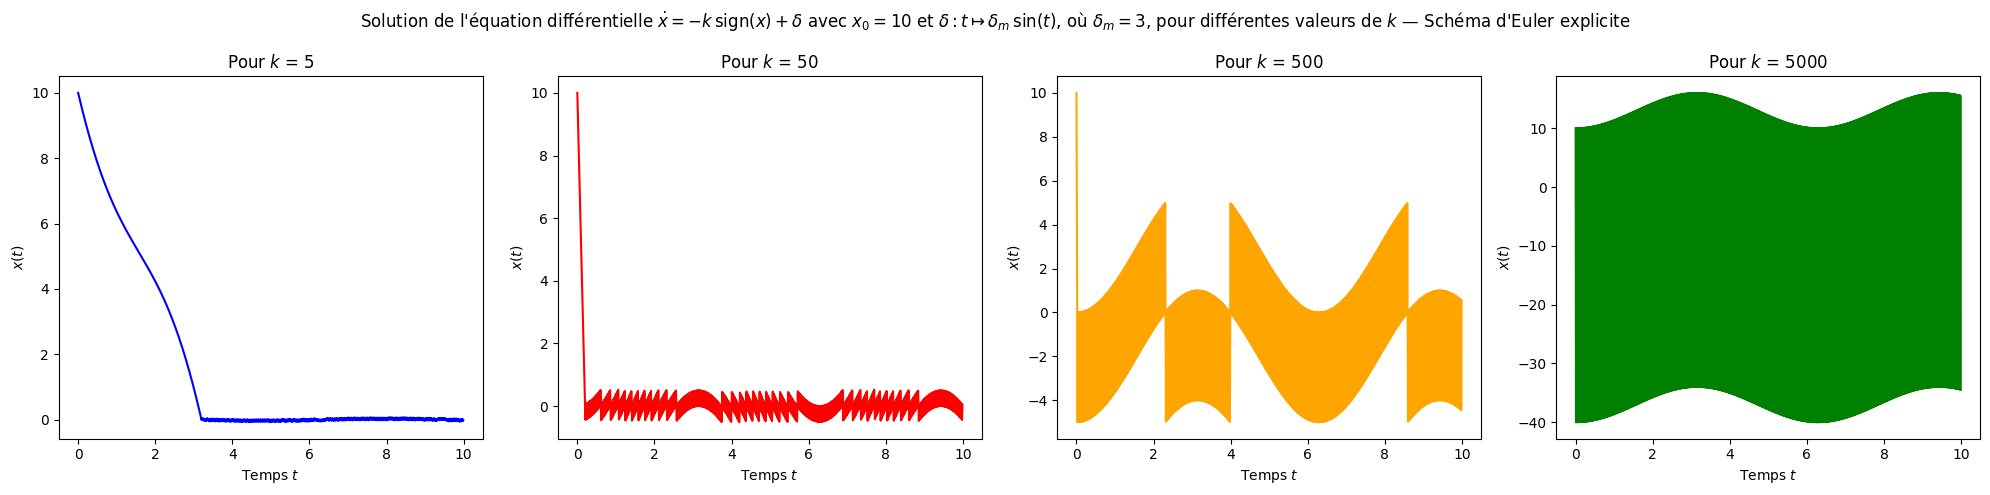

In [25]:
def f_k(k) :
    def f(x, t):
        delta_m = 3
        delta = delta_m * np.sin(t)
        return -k * np.sign(x) + delta
    return f
t0 = 0
tf = 10
dt = 0.01
x0 = 10
k = [5, 50, 500, 5000]
fig, axes = plt.subplots(nrows=1, ncols=4,figsize=(20, 5))
colors = ['blue', 'red', 'orange', 'green']
for i in range(4) :
    t, x = euler_explicit(f_k(k[i]), x0, t0, tf, dt)
    axes[i].plot(t, x, color=colors[i])
    axes[i].set_xlabel("Temps $t$")
    axes[i].set_ylabel("$x(t)$")
    axes[i].set_title(f"Pour $k$ = {k[i]}")
fig.suptitle(r"Solution de l'équation différentielle $\dot{x} = - k \, {\rm sign}(x) + \delta$ avec $x_0 = 10$ et $\delta : t \mapsto \delta_m \, {\rm sin}(t)$, où $\delta_m = 3$, pour différentes valeurs de $k$ — Schéma d'Euler explicite")
plt.tight_layout()
plt.show()

On note que plus $k$ est grand, plus le phénomène de *chattering* est marqué. Si l'on peut considérer à l'échelle de l'unité qu'il est acceptable pour $k$ petit ($k = 5$, variations peu perceptibles), il devient totalement inacceptable pour $k$ grand ($k = 500$ et $k = 5000$, variation de plusieurs unités voire dizaines d'unités autour de $0$).


**Schéma d'Euler implicite**

Pour ce système, l'équation implicite du schéma d'Euler est, avec des notations usuelles : $x_{n+1} = x_n + \Delta t \, (- k \, {\rm sign}(x_{n+1}) + \delta(t_{n+1}))$.

L'algorithme proposé repose sur la disjonction de cas suivante :


**Cas 1 : $x_{n+1} > 0$.**

Alors ${\rm sign}(x_{n+1}) = 1$, et $x_{n+1} = x_n + \Delta t \, (- k + \delta(t_{n+1}))$. L'hypothèse est donc vérifée si $x_n + \Delta t \, \delta(t_{n+1})> \Delta t \, k$.


**Cas 2 : $x_{n+1} < 0$.**

Alors ${\rm sign}(x_{n+1}) = -1$, et $x_{n+1} = x_n + \Delta t \, (k + \delta(t_{n+1}))$. L'hypothèse est donc vérifée si $x_n + \Delta t \, \delta(t_{n+1}) < - \Delta t \, k$.


**Cas 3 : $x_{n+1} = 0$.**

Alors ${\rm sign}(x_{n+1}) = [-1, 1]$, et $x_n + \Delta t \, \delta(t_{n+1}) \in [- \Delta t \, k, \Delta t \, k]$, qui est donc la condition de validité de l'hypothèse.


Ainsi, pour déterminer $x_{n+1}$, on évalue la quantité $x_n + \Delta t \, \delta(t_{n+1})$, qu'on compare à $- \Delta t \, k$ et à $\Delta t \, k$, ce qui permet d'obtenir une formule explicite pour $x_{n+1}$.

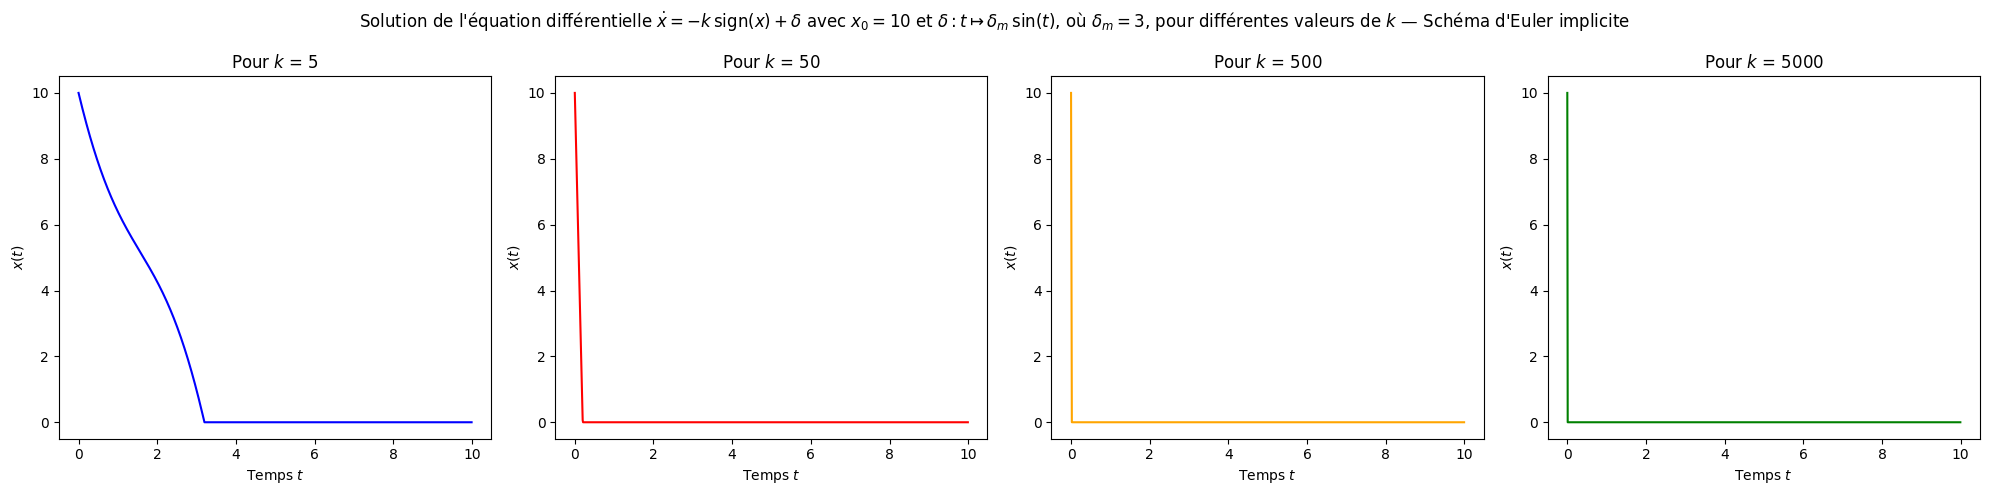

In [ ]:
def euler_implicit_sliding(x0,t0,tf,dt,k,delta): # on ajoute les paramètres k et delta
    time = np.arange(t0, tf, dt)
    sol = np.zeros(len(time))
    sol[0] = x0
    for i in range(len(time) - 1) :
        sol_aux = sol[i] + dt * delta(t[i+1])
        if sol_aux > dt * k :
            sol[i+1] = sol[i] + dt * (-k + delta(t[i+1]))
        elif sol_aux < - dt * k :
            sol[i+1] = sol[i] + dt * (k + delta(t[i+1]))
        else :
            sol[i+1] = 0
    return time, sol

## Affichage graphique

def delta(t) :
    delta_m = 3
    return delta_m * np.sin(t)
t0 = 0
tf = 10
dt = 0.01
x0 = 10
k = [5, 50, 500, 5000]
fig, axes = plt.subplots(nrows=1, ncols=4,figsize=(20, 5))
colors = ['blue', 'red', 'orange', 'green']
for i in range(4) :
    t, x = euler_implicit_sliding(x0, t0, tf, dt, k[i], delta)
    axes[i].plot(t, x, color=colors[i])
    axes[i].set_xlabel("Temps $t$")
    axes[i].set_ylabel("$x(t)$")
    axes[i].set_title(f"Pour $k$ = {k[i]}")
fig.suptitle(r"Solution de l'équation différentielle $\dot{x} = - k \, {\rm sign}(x) + \delta$ avec $x_0 = 10$ et $\delta : t \mapsto \delta_m \, {\rm sin}(t)$, où $\delta_m = 3$, pour différentes valeurs de $k$ — Schéma d'Euler implicite")
plt.tight_layout()
plt.show()

Ainsi, le schéma d'Euler implicite permet d'éviter le phénomène de *chattering* et d'assurer une convergence numérique exacte vers $0$ quelle que soit la valeur de $k$, comme on l'observe sur les courbes ci-dessus (solutions exactement nulles à partir d'une certaine valeur de $t$). On peut vérifier qu'il en est de même quelle que soit la valeur de $x_0$.

**Question 8** Application : donner un exemple physique d'un oscillateur évoluant selon
$$
\begin{array}{rcl}
\dot{x}_1 &=& x_2 \\
\dot{x}_2 &=& -x_1 - k {\rm sign}(x_2)  
\end{array}
$$
et proposer un schéma numérique pour simuler son comportement.

In [ ]:
def euler_implicit_friction(x0,t0,tf,dt):
    
    return time, sol